# Conditional Diffusion on MNIST: Classifier-Free Guidance

The unconditional DDPM in notebook 10 learned to generate *a digit*. Here we ask for a particular digit by learning the class-conditional distribution $p_\theta(x_0\mid y)$, where $y\in\{0,\ldots,9\}$.

### Learning goals

1. Distinguish **classifier guidance** from **classifier-free guidance** (CFG).
2. Understand why classifier guidance needs a separate, noise-aware classifier.
3. Train one denoiser to make conditional and unconditional predictions using **label dropout**.
4. Implement
   $$\hat\epsilon_{\mathrm{cfg}}=\hat\epsilon_{\varnothing}+s(\hat\epsilon_y-\hat\epsilon_{\varnothing}).$$
5. Generate requested MNIST classes and study the fidelity--diversity trade-off controlled by $s$.

The forward diffusion process is unchanged. Only the denoiser and the way it is queried during sampling become conditional.


## Before you begin

**Prerequisites.** Know the DDPM forward/reverse equations from notebook 10, conditional probability, embeddings, and ancestral sampling. Notebook 05 gives the ring-level diffusion foundation. Notebook 10 is the direct image-scale predecessor.

> **Notation and orientation**
> - $y\in\{0,\ldots,9\}$ is a class, $\varnothing$ is the learned null condition, and $s$ is the classifier-free guidance (CFG) scale.
> - **Unchanged from unconditional image diffusion:** $q(x_t\mid x_0)$, the noise target, schedule, and reverse variance.
> - **Changed by conditioning:** label dropout during training and two denoiser predictions per guided reverse step. Image-scale spatial denoising itself is unchanged.

## 1. Setup and configuration

This notebook has the same small, from-scratch PyTorch style as notebook 10. It supports launching Jupyter from either the repository root or `notebooks/`.

A separate checkpoint is necessary. This network has class embeddings and must be trained with label dropout, so the unconditional checkpoint is not a drop-in replacement.

>**Run modes:** `RUN_MODE = "lecture"` (the default) loads the bundled checkpoint and avoids retraining. Use `"full"` to train the documented configuration, or `"smoke"` for a reduced CPU pipeline check. Smoke-mode checkpoints and results are deliberately separate and are **not** representative model results.


In [ ]:
import copy
import gzip
import random
import struct
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 11
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
RUN_MODE = "lecture"  # "lecture", "full", or "smoke"
if RUN_MODE not in {"lecture", "full", "smoke"}:
    raise ValueError("RUN_MODE must be 'lecture', 'full', or 'smoke'.")
TRAIN = RUN_MODE != "lecture"
EPOCHS = 1 if RUN_MODE == "smoke" else 30
BATCH_SIZE = 128
LEARNING_RATE = 2e-4
T = 50 if RUN_MODE == "smoke" else 300
BASE_CHANNELS = 16 if RUN_MODE == "smoke" else 32
N_CLASSES = 10
NULL_CLASS = N_CLASSES    # Learned token 10 means "no class condition".
CONDITION_DROP_PROB = 0.15

NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
checkpoint_name = "ddpm_mnist_cfg_smoke.pt" if RUN_MODE == "smoke" else "ddpm_mnist_cfg.pt"
CHECKPOINT = NOTEBOOK_DIR / "checkpoints" / checkpoint_name
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(
    f"PyTorch {torch.__version__} | device: {DEVICE} | "
    f"run mode: {RUN_MODE} | checkpoint: {CHECKPOINT}"
)
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")


## 2. Load labeled MNIST

Unlike unconditional training, each mini-batch needs an image $x_0$ and its class $y$. Images are mapped from $[0,1]$ to $[-1,1]$, matching the range used by the model and display utilities.


In [17]:
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        print(f"Downloading {filename} ...")
        urlretrieve(BASE_URL + filename, destination)


def read_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, columns = struct.unpack(">IIII", file.read(16))
        assert magic == 2051
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    images = torch.from_numpy(array.reshape(count, 1, rows, columns)).float() / 255
    return images * 2 - 1


def read_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        assert magic == 2049
        array = np.frombuffer(file.read(), dtype=np.uint8).copy()
    return torch.from_numpy(array.astype(np.int64))


x_train = read_idx_images(DATA_DIR / FILES["train_images"])
y_train = read_idx_labels(DATA_DIR / FILES["train_labels"])
x_test = read_idx_images(DATA_DIR / FILES["test_images"])
y_test = read_idx_labels(DATA_DIR / FILES["test_labels"])
train_count = len(x_train) if RUN_MODE != "smoke" else min(2_048, len(x_train))
train_dataset = TensorDataset(x_train[:train_count], y_train[:train_count])
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    pin_memory=PIN_MEMORY, generator=torch.Generator().manual_seed(SEED),
)
print(f"Training: {tuple(x_train.shape)}, {tuple(y_train.shape)}")
print(f"Test:     {tuple(x_test.shape)}, {tuple(y_test.shape)}")


Training: (60000, 1, 28, 28), (60000,)
Test:     (10000, 1, 28, 28), (10000,)


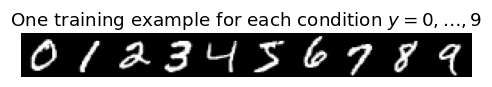

In [18]:
def show_image_grid(images, nrow=10, title=None, value_range=(-1, 1)):
    """Display NCHW or NHW tensors without torchvision."""
    images = images.detach().cpu()
    if images.ndim == 4:
        images = images[:, 0]
    ncol = int(np.ceil(len(images) / nrow))
    canvas = torch.full(
        (ncol * 28 + ncol - 1, nrow * 28 + nrow - 1),
        float(value_range[0]), dtype=images.dtype,
    )
    for index, image in enumerate(images):
        row, column = divmod(index, nrow)
        canvas[row * 29 : row * 29 + 28, column * 29 : column * 29 + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


example_indices = [int(torch.where(y_train == digit)[0][0]) for digit in range(10)]
show_image_grid(
    x_train[example_indices], nrow=10,
    title="One training example for each condition $y=0,\\ldots,9$",
)


## 3. The forward process does not depend on the label

For a variance schedule $\beta_1,\ldots,\beta_T$, let $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$. We can jump directly to any noise level:

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

The class does not appear in $q(x_t\mid x_0)$. It supplies information only to the learned reverse process $p_\theta(x_{t-1}\mid x_t,y)$.


In [19]:
def cosine_beta_schedule(n_steps, offset=0.008):
    """Cosine schedule from Nichol & Dhariwal (2021)."""
    steps = torch.arange(n_steps + 1, dtype=torch.float64)
    f = torch.cos(((steps / n_steps + offset) / (1 + offset)) * torch.pi / 2).square()
    alpha_bar = f / f[0]
    return (1 - alpha_bar[1:] / alpha_bar[:-1]).clamp(1e-5, 0.999).float()


betas = cosine_beta_schedule(T).to(DEVICE)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)


def extract(values, t, target):
    """Gather one schedule value per image and add broadcast dimensions."""
    return values.gather(0, t).reshape(len(t), *([1] * (target.ndim - 1)))


def q_sample(x0, t, noise=None):
    """Draw x_t directly from q(x_t | x_0)."""
    noise = torch.randn_like(x0) if noise is None else noise
    x_t = extract(sqrt_alpha_bars, t, x0) * x0 + extract(
        sqrt_one_minus_alpha_bars, t, x0
    ) * noise
    return x_t, noise


print(
    f"steps: {T} | beta range: [{betas[0].item():.2e}, {betas[-1].item():.3f}] | "
    f"final signal power: {alpha_bars[-1].item():.2e}"
)


steps: 300 | beta range: [1.56e-04, 0.999] | final signal power: 2.70e-08


## 4. Classifier guidance: a separate classifier (theory only)

Classifier guidance starts with an **unconditional** diffusion model and a classifier $p_\phi(y\mid x_t,t)$ trained to recognize deliberately noised images at every diffusion time. Bayes' rule gives

$$
\nabla_{x_t}\log p_t(x_t\mid y)
=
\nabla_{x_t}\log p_t(x_t)
+
\nabla_{x_t}\log p_\phi(y\mid x_t,t).
$$

A scale strengthens the classifier term. An epsilon model represents the score as

$$\nabla_{x_t}\log p_t(x_t)\approx-\hat\epsilon_\theta(x_t,t)/\sqrt{1-\bar\alpha_t},$$

so the classifier gradient can shift the score, equivalently the predicted noise, in each reverse step.

### Why it is not implemented here

- It requires a **second network**, trained on noisy examples across every $t$ rather than only clean MNIST.
- Each step requires $\nabla_{x_t}\log p_\phi(y\mid x_t,t)$, so classifier-input autograd is needed during sampling.
- Guidance can exploit adversarial classifier directions rather than improve perceptual quality.
- Classifier calibration near pure noise adds another component to tune and diagnose.

Classifier guidance is historically important and makes the score identity explicit. We instead implement classifier-free guidance, which learns both estimates in one denoiser and needs no classifier gradient.


## 5. Classifier-free guidance (CFG)

During training, we can replace the true label with a null token $\varnothing$ with probability $p_{\mathrm{drop}}$:

$$
\tilde y=\begin{cases}\varnothing&\text{with probability }p_{\mathrm{drop}},\\y&\text{otherwise},\end{cases}
\qquad
\mathcal L=\mathbb E\left[\|\epsilon-\epsilon_\theta(x_t,t,\tilde y)\|_2^2\right].
$$

One network learns $\epsilon_\theta(x_t,t,\varnothing)$ (unconditional) and $\epsilon_\theta(x_t,t,y)$ (conditional). At sampling time:

$$\epsilon_{\mathrm{cfg}}=\epsilon_{\varnothing}+s(\epsilon_y-\epsilon_{\varnothing}).$$

With this convention, $s=0$ is unconditional, $s=1$ is the ordinary conditional model, and $s>1$ extrapolates toward features distinguishing $y$ from the full population. Some papers write $(1+w)\epsilon_y-w\epsilon_{\varnothing}$. It is the same line with $s=1+w$, but check conventions before comparing scales.


## 6. A class- and time-conditioned U-Net

The architecture mirrors notebook 10. A sinusoidal time embedding and learned class embedding are mapped to the same dimension and added. Every residual block receives that vector.

`NULL_CLASS = 10` is not an MNIST class. It has a learned embedding representing absent class information. Treating digit 0 as “unconditional” would incorrectly entangle two tasks.


In [20]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim % 2 == 0
        frequencies = torch.exp(-np.log(10_000) * torch.arange(dim // 2) / (dim // 2 - 1))
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        return torch.cat([angles.sin(), angles.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, condition_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.condition_projection = nn.Linear(condition_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x, condition):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.condition_projection(condition)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class ConditionalUNet(nn.Module):
    def __init__(self, base=32, condition_dim=128, n_classes=10):
        super().__init__()
        self.null_class = n_classes
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base * 2), nn.Linear(base * 2, condition_dim),
            nn.SiLU(), nn.Linear(condition_dim, condition_dim),
        )
        self.class_embedding = nn.Embedding(n_classes + 1, condition_dim)
        self.class_mlp = nn.Sequential(nn.SiLU(), nn.Linear(condition_dim, condition_dim))
        self.input_conv = nn.Conv2d(1, base, 3, padding=1)
        self.down_block1 = ResBlock(base, base, condition_dim)
        self.downsample1 = nn.Conv2d(base, base * 2, 4, stride=2, padding=1)
        self.down_block2 = ResBlock(base * 2, base * 2, condition_dim)
        self.downsample2 = nn.Conv2d(base * 2, base * 4, 4, stride=2, padding=1)
        self.middle1 = ResBlock(base * 4, base * 4, condition_dim)
        self.middle2 = ResBlock(base * 4, base * 4, condition_dim)
        self.upsample2 = nn.ConvTranspose2d(base * 4, base * 2, 4, stride=2, padding=1)
        self.up_block2 = ResBlock(base * 4, base * 2, condition_dim)
        self.upsample1 = nn.ConvTranspose2d(base * 2, base, 4, stride=2, padding=1)
        self.up_block1 = ResBlock(base * 2, base, condition_dim)
        self.output_norm = nn.GroupNorm(8, base)
        self.output_conv = nn.Conv2d(base, 1, 3, padding=1)

    def forward(self, x, t, labels):
        if labels.ndim != 1 or len(labels) != len(x):
            raise ValueError("labels must have shape (batch,)")
        condition = self.time_mlp(t) + self.class_mlp(self.class_embedding(labels))
        h0 = self.input_conv(x)
        h1 = self.down_block1(h0, condition)
        h2 = self.down_block2(self.downsample1(h1), condition)
        h = self.middle2(self.middle1(self.downsample2(h2), condition), condition)
        h = self.up_block2(torch.cat([self.upsample2(h), h2], dim=1), condition)
        h = self.up_block1(torch.cat([self.upsample1(h), h1], dim=1), condition)
        return self.output_conv(F.silu(self.output_norm(h)))


model = ConditionalUNet(base=BASE_CHANNELS, n_classes=N_CLASSES).to(DEVICE)
test_x = torch.randn(4, 1, 28, 28, device=DEVICE)
test_t = torch.randint(T, (4,), device=DEVICE)
test_labels = torch.tensor([0, 3, 7, NULL_CLASS], device=DEVICE)
with torch.no_grad():
    test_output = model(test_x, test_t, test_labels)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Shape check:", tuple(test_output.shape))


Parameters: 1,262,625
Shape check: (4, 1, 28, 28)


## 7. Train conditional and unconditional branches together

Label dropout is independent for each example and visit. The null branch sees a random subset of the full distribution, not special classes. Too little dropout undertrains $\epsilon_{\varnothing}$. Too much leaves fewer conditional updates. Values around $0.1$-$0.2$ are common starting points. We use $0.15$ here.

The exponential moving average (EMA) model is again used for sampling because it usually yields a smoother denoising field.

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)
history = []


def update_ema(target, source, decay=0.995):
    with torch.no_grad():
        for target_parameter, source_parameter in zip(target.parameters(), source.parameters()):
            target_parameter.lerp_(source_parameter, 1 - decay)
        for target_buffer, source_buffer in zip(target.buffers(), source.buffers()):
            target_buffer.copy_(source_buffer)


def drop_labels(labels, probability):
    """Replace labels by the learned null token for CFG training."""
    dropped = labels.clone()
    mask = torch.rand(labels.shape, device=labels.device) < probability
    dropped[mask] = NULL_CLASS
    return dropped, mask


if not TRAIN:
    if not CHECKPOINT.exists():
        raise FileNotFoundError(f"No checkpoint at {CHECKPOINT}; use RUN_MODE='full' first.")
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    ema_model.load_state_dict(checkpoint["ema_model"])
    history = checkpoint["history"]
    print(f"Loaded {CHECKPOINT} after epoch {checkpoint['epoch']}")
else:
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        total_dropped = 0
        for x0, labels in train_loader:
            x0 = x0.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            t = torch.randint(T, (len(x0),), device=DEVICE)
            x_t, noise = q_sample(x0, t)
            training_labels, drop_mask = drop_labels(labels, CONDITION_DROP_PROB)
            loss = F.mse_loss(model(x_t, t, training_labels), noise)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            update_ema(ema_model, model)
            total_loss += loss.item() * len(x0)
            total_dropped += int(drop_mask.sum())

        average_loss = total_loss / len(train_loader.dataset)
        history.append(average_loss)
        print(
            f"epoch {epoch:2d}/{EPOCHS} | noise MSE {average_loss:.4f} | "
            f"null labels {total_dropped / len(train_loader.dataset):.1%}"
        )
        torch.save({
            "model": model.state_dict(), "ema_model": ema_model.state_dict(),
            "history": history, "epoch": epoch,
            "config": {"T": T, "base_channels": BASE_CHANNELS,
                       "condition_drop_prob": CONDITION_DROP_PROB, "null_class": NULL_CLASS},
        }, CHECKPOINT)
    print(f"Training time: {(time.time() - start) / 60:.1f} min")


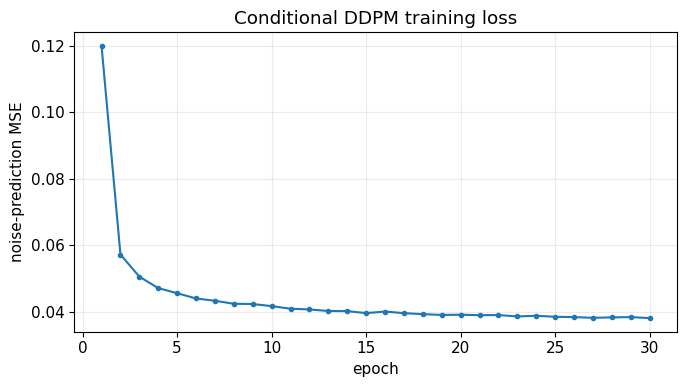

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(history) + 1), history, marker="o", markersize=3)
ax.set(xlabel="epoch", ylabel="noise-prediction MSE", title="Conditional DDPM training loss")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Implement the CFG noise estimate

The equation needs two evaluations of the **same network** at the same $(x_t,t)$: one with the null token and one with the requested class. We concatenate the batches to perform one batched forward call. This improves hardware utilization but still processes twice as many examples as unguided prediction.

The difference $\epsilon_y-\epsilon_{\varnothing}$ is a learned condition direction. CFG extrapolates along it. It is not equivalent to multiplying a class embedding.


### Predict before running

>**Commit to a prediction:** under this notebook’s convention, what should $s=0$ and $s=1$ recover, and how should the RMS of the guided noise estimate change as $s$ grows? Justify from the CFG equation.

In [23]:
@torch.no_grad()
def predict_noise_cfg(model, x_t, t, labels, guidance_scale=3.0):
    """Combine unconditional and conditional epsilon predictions."""
    if labels.shape != (len(x_t),):
        raise ValueError("labels must have one class index per image")
    if not torch.all((0 <= labels) & (labels < N_CLASSES)):
        raise ValueError(f"requested labels must be in [0, {N_CLASSES - 1}]")
    null_labels = torch.full_like(labels, NULL_CLASS)
    epsilon_unconditional, epsilon_conditional = model(
        torch.cat([x_t, x_t]), torch.cat([t, t]),
        torch.cat([null_labels, labels]),
    ).chunk(2)
    return epsilon_unconditional + guidance_scale * (
        epsilon_conditional - epsilon_unconditional
    )


ema_model.eval()
probe_x = torch.randn(3, 1, 28, 28, device=DEVICE)
probe_t = torch.full((3,), T // 2, device=DEVICE, dtype=torch.long)
probe_y = torch.tensor([1, 4, 8], device=DEVICE)
for scale in [0.0, 1.0, 3.0]:
    estimate = predict_noise_cfg(ema_model, probe_x, probe_t, probe_y, scale)
    print(f"scale {scale:>3.1f} | epsilon RMS {estimate.square().mean().sqrt().item():.3f}")


scale 0.0 | epsilon RMS 1.273
scale 1.0 | epsilon RMS 1.274
scale 3.0 | epsilon RMS 1.319


>**Expected observation / interpretation.** $s=0$ recovers the null/unconditional prediction and $s=1$ the ordinary conditional prediction. Larger $s$ extrapolates along $\epsilon_y-\epsilon_\varnothing$, often increasing the estimate’s magnitude. The exact trend depends on time and batch.

## 9. Put CFG inside the DDPM reverse step

From guided noise, estimate

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon_{\mathrm{cfg}}}{\sqrt{\bar\alpha_t}}.$$

Then use the exact forward-posterior coefficients for the DDPM mean and add posterior noise for $t>1$. Clipping $\hat x_0$ to $[-1,1]$ is a practical stabilization, especially at large scales.


In [24]:
alpha_bars_previous = torch.cat([torch.ones(1, device=DEVICE), alpha_bars[:-1]])
posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)
posterior_mean_coefficient_x0 = betas * torch.sqrt(alpha_bars_previous) / (1 - alpha_bars)
posterior_mean_coefficient_xt = torch.sqrt(alphas) * (1 - alpha_bars_previous) / (1 - alpha_bars)


def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


@torch.no_grad()
def p_sample_cfg(model, x_t, t_index, labels, guidance_scale, generator=None):
    """Sample one guided transition p_theta(x_{t-1} | x_t, y)."""
    t = torch.full((len(x_t),), t_index, device=DEVICE, dtype=torch.long)
    predicted_noise = predict_noise_cfg(model, x_t, t, labels, guidance_scale)
    predicted_x0 = (
        x_t - sqrt_one_minus_alpha_bars[t_index] * predicted_noise
    ) / sqrt_alpha_bars[t_index]
    predicted_x0 = predicted_x0.clamp(-1, 1)
    mean = posterior_mean_coefficient_x0[t_index] * predicted_x0 + posterior_mean_coefficient_xt[t_index] * x_t
    if t_index == 0:
        return mean
    noise = torch.randn(x_t.shape, device=x_t.device, dtype=x_t.dtype, generator=generator)
    return mean + torch.sqrt(posterior_variance[t_index]) * noise


@torch.no_grad()
def sample_ddpm_cfg(model, labels, guidance_scale=3.0, initial_noise=None, seed=0, snapshot_steps=()):
    """Run the complete class-conditional ancestral DDPM chain."""
    model.eval()
    labels = torch.as_tensor(labels, dtype=torch.long, device=DEVICE)
    generator = make_generator(seed)
    if initial_noise is None:
        x = torch.randn(len(labels), 1, 28, 28, device=DEVICE, generator=generator)
    else:
        expected_shape = (len(labels), 1, 28, 28)
        if tuple(initial_noise.shape) != expected_shape:
            raise ValueError(f"initial_noise must have shape {expected_shape}")
        x = initial_noise.to(DEVICE).clone()
    snapshots = {T: x.cpu()} if T in snapshot_steps else {}
    for t_index in reversed(range(T)):
        x = p_sample_cfg(model, x, t_index, labels, guidance_scale, generator)
        if t_index in snapshot_steps:
            snapshots[t_index] = x.cpu()
    return x.cpu(), snapshots


## 10. Guidance-scale sweep with controlled randomness

Every row below starts from the same $x_T$ and uses the same seed for ancestral reverse noise. Only $s$ changes.

- $s=0$: requested labels are ignored because only the null prediction remains;
- $s=1$: ordinary class-conditional samples;
- moderate $s>1$: class evidence is often clearer;
- very large $s$: samples may become stereotyped or distorted.

No scale is universally best. It depends on the model, condition-drop probability, sampler, and desired balance between adherence and diversity.


### Predict before running

>**Commit to a prediction:** as guidance scale increases under controlled initial noise, what will happen to requested-class fidelity and within-class diversity? Justify why an extreme scale is not necessarily the best choice.

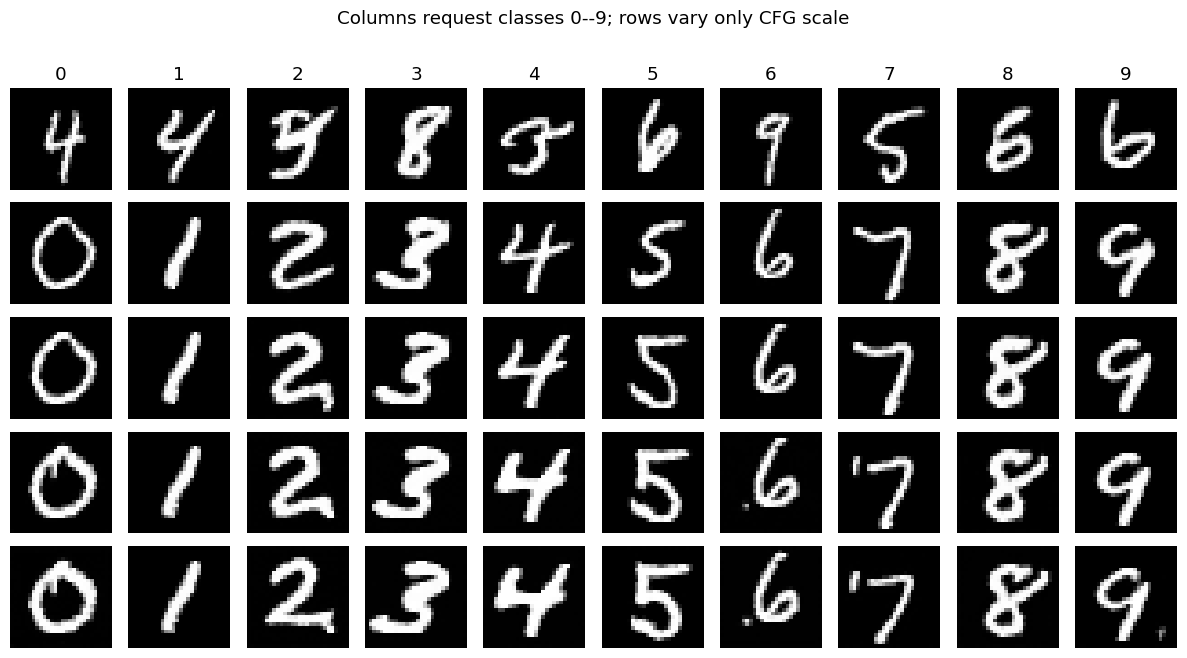

In [25]:
target_labels = torch.arange(10, device=DEVICE)
shared_noise = torch.randn(10, 1, 28, 28, device=DEVICE, generator=make_generator(2026))
guidance_scales = [0.0, 1.0, 2.0, 4.0, 7.0]
guidance_samples = {}
for scale in guidance_scales:
    guidance_samples[scale], _ = sample_ddpm_cfg(
        ema_model, target_labels, guidance_scale=scale,
        initial_noise=shared_noise, seed=31415,
    )

fig, axes = plt.subplots(len(guidance_scales), 10, figsize=(12, 6.5))
for row, scale in enumerate(guidance_scales):
    for column in range(10):
        axes[row, column].imshow(
            guidance_samples[scale][column, 0].clamp(-1, 1),
            cmap="gray", vmin=-1, vmax=1,
        )
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(str(column))
    axes[row, 0].set_ylabel(f"s={scale:g}", rotation=0, ha="right", va="center")
plt.suptitle("Columns request classes 0--9; rows vary only CFG scale", y=1.01)
plt.tight_layout()
plt.show()


>**Expected observation / interpretation.** Moderate guidance usually strengthens class-specific strokes and adherence, while high guidance can reduce stylistic diversity or introduce artifacts. Holding initial noise fixed makes changes attributable to $s$, not a different latent draw.

## 11. Generate several examples of every requested class

A scale near 3 is a reasonable starting point, but the sweep should determine whether it suits the trained checkpoint. In the following plots, each column requests one digit, and each row shows one independently generated sample per class.

Class consistency and diversity are different objectives. A useful model should obey the row label **without** producing the same handwriting every time.


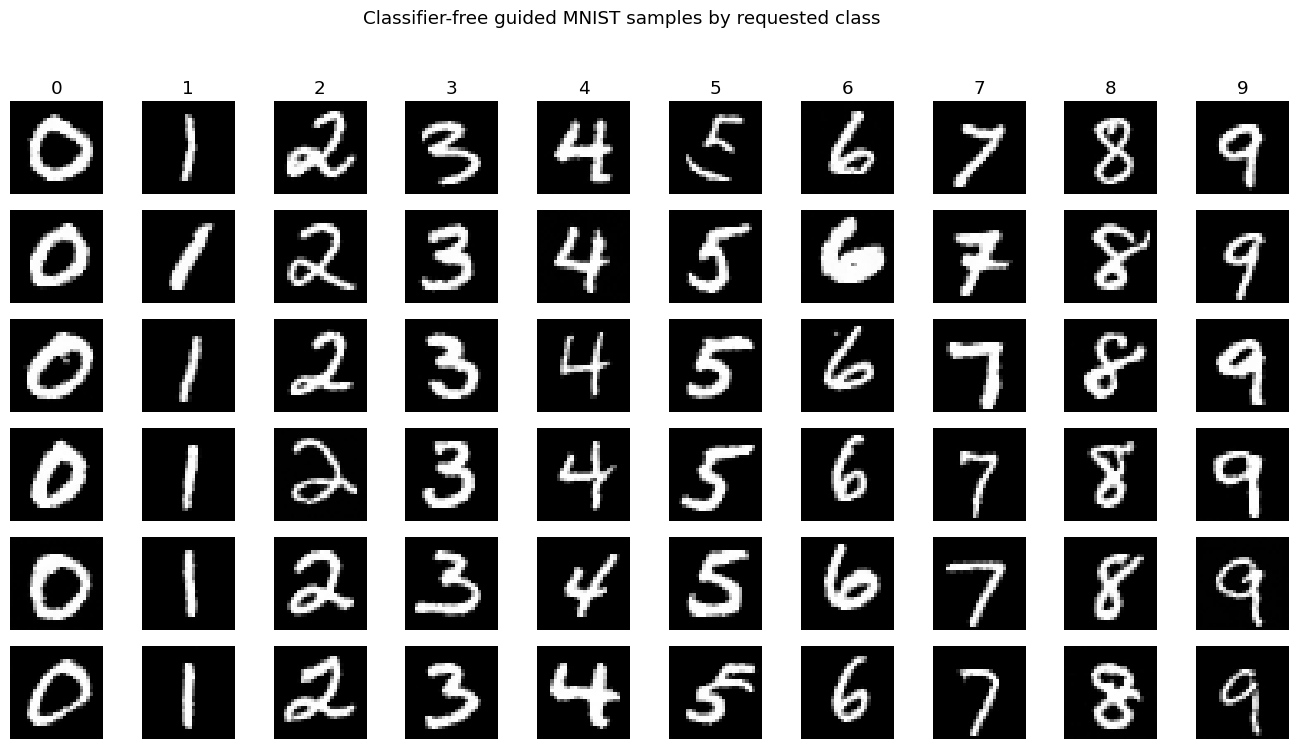

In [26]:
samples_per_class = 6
labels = torch.arange(10).repeat_interleave(samples_per_class)
conditional_samples, _ = sample_ddpm_cfg(ema_model, labels, guidance_scale=3.0, seed=2718)

fig, axes = plt.subplots(samples_per_class, 10, figsize=(14, 7.5))
for digit in range(10):
    for row in range(samples_per_class):
        index = digit * samples_per_class + row
        axes[row, digit].imshow(
            conditional_samples[index, 0].clamp(-1, 1),
            cmap="gray", vmin=-1, vmax=1,
        )
        axes[row, digit].axis("off")
    axes[0, digit].set_title(str(digit))
for row in range(samples_per_class):
    axes[row, 0].set_ylabel(f"Sample {row + 1}", rotation=0, ha="right", va="center")
fig.suptitle("Classifier-free guided MNIST samples by requested class", y=0.995)
fig.tight_layout(rect=(0.04, 0, 1, 0.97))
plt.show()


## 12. What CFG buys—and what it costs

| Method | Networks | Training requirement | Sampling signal | Main risk |
|---|---:|---|---|---|
| Unconditional DDPM | one denoiser | noise prediction | none | no class control |
| Classifier guidance | denoiser + classifier | noisy classifier across all $t$ | classifier gradient | adversarial/miscalibrated gradients |
| Classifier-free guidance | one conditional denoiser | random condition dropout | conditional minus null prediction | extra denoiser work, diversity loss at high scale |

### Important implementation details

1. **Train the null branch.** Supplying a null token only at inference is not CFG.
2. **Use the same $x_t$ and $t$ for both branches.** Otherwise their difference mixes condition and noise.
3. **Keep the null token distinct.** It is not digit 0.
4. **Remember the convention.** Here $s=1$ is the standard conditional prediction.
5. **Control randomness when comparing scales.** Otherwise guidance is confounded with latent variation.
6. **Do not assume stronger is better.** Large scales can improve adherence while reducing style coverage.
7. **Count computation honestly.** One concatenated call still evaluates a doubled batch.


## Takeaways and homework experiments

### Takeaways

Classifier guidance gets a conditional score from an unconditional denoiser plus a separate classifier gradient. CFG trains one denoiser to make conditional and unconditional predictions. Their difference points toward the requested condition. Extrapolating along it trades diversity for stronger adherence without training or differentiating through a classifier.

### Mini-experiment 1 — Guidance signal over time
- **Hypothesis:** $\|\epsilon_y-\epsilon_\varnothing\|_2$ changes systematically with noise level because class evidence is not equally available at every $t$.
- **Metric/plot:** Plot mean and spread of the guidance-vector RMS against diffusion time, optionally split by class.
- **Controls:** Reuse one checkpoint and a fixed balanced image/noise batch. Use the same $x_t$ and $t$ for both branches.
- **Interpretation:** Relate where conditioning is strongest to image signal-to-noise. Do not treat norm alone as quality.

### Mini-experiment 2 — CFG under deterministic DDIM
- **Hypothesis:** Removing ancestral reverse noise makes the scale-driven fidelity–diversity trade-off easier to isolate for fixed $x_T$.
- **Metric/plot:** Plot target-class accuracy and within-class feature diversity versus $s$, with matched deterministic sample grids.
- **Controls:** Fix checkpoint, DDIM state schedule, $x_T$, labels, evaluator, and sample count across scales.
- **Interpretation:** Attribute changes to guidance, while remembering that diversity across initial latents can remain. 

### Extensions
- Sweep `CONDITION_DROP_PROB` over $\{0.05,0.1,0.2,0.5\}$ and assess both $s=0$ and $s>1$.
- Replace addition of time and class embeddings with concatenation plus an MLP.
- Measure target-class accuracy and within-class feature diversity on thousands of samples.
- Try a scale schedule $s(t)$ instead of one constant scale.


## Exit ticket

1. How does classifier-free guidance differ from classifier guidance?
<details><summary>Self-check</summary>CFG combines conditional and null predictions from one dropout-trained denoiser. Classifier guidance adds a separate noisy-classifier gradient.</details>

2. Under this convention, what do $s=0$ and $s=1$ mean?
<details><summary>Self-check</summary>$s=0$ is the null/unconditional prediction. $s=1$ is the ordinary conditional prediction.</details>

3. Why can increasing $s$ improve fidelity but reduce diversity?
<details><summary>Self-check</summary>Extrapolation strengthens condition-specific score directions, which can concentrate samples into fewer styles and amplify errors at high scale.</details>

## References and further reading

- [Dhariwal & Nichol, “Diffusion Models Beat GANs on Image Synthesis” (NeurIPS 2021)](https://proceedings.neurips.cc/paper/2021/hash/49ad23d1ec9fa4bd8d77d02681df5cfa-Abstract.html): Establishes classifier guidance with a noise-aware classifier.
- [Ho & Salimans, “Classifier-Free Diffusion Guidance” (2022)](https://arxiv.org/abs/2207.12598): Foundational source for joint conditional/unconditional training and CFG interpolation.
- [Hugging Face Diffusion Course, guidance chapter](https://huggingface.co/learn/diffusion-course/unit2/3): An accessible implementation-oriented explanation of guidance scale.